In [3]:
import numpy as np
import matplotlib.pyplot as plt
import time
import torch
import h5py
from scipy.ndimage import gaussian_filter
import pickle
import pandas as pd
from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference import SNPE, prepare_for_sbi, simulate_for_sbi, SNLE, MCMCPosterior, likelihood_estimator_based_potential, SNPE_A
from sbi.utils.get_nn_models import posterior_nn, likelihood_nn
from sbi.neural_nets.embedding_nets import FCEmbedding
from sbi.inference.base import infer
import seaborn as sns
import csv
from CosmoFuse.visualisation import make_corner_plot

2024-04-08 14:39:20.406454: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-08 14:39:22.418169: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [ ]:
class CosmoGridWide(torch.distributions.Distribution):

    def __init__(self, device='cpu'):
        self.low, self.high = torch.Tensor([0.1, 0.4]).to(device), torch.Tensor([0.5, 1.4]).to(device)
        self.device = device
        super().__init__(2, validate_args=None)

    def check(self, value):
        if value[1] < -2.5*value[0]+1.15:
            return False
        if value[1] > -2.5*value[0]+1.9:
            return False
        return True

    def rsample(self, shape=torch.Size()):
        #check wether shape is a tuple or an int
        if isinstance(shape, int):
            shape = torch.Size((shape,2))
        if len(shape) == 1:
            shape = torch.Size((shape[0],2))
        
        rand = torch.rand(shape, dtype=self.low.dtype, device=self.low.device)
        samples = self.low + rand * (self.high - self.low)
        for i, sample in enumerate(samples):
            while not self.check(sample):
                rand = torch.rand(2, dtype=self.low.dtype, device=self.low.device)
                sample = self.low + rand * (self.high - self.low)
                samples[i] = sample
        return samples

    def log_prob(self, value):
        if value.shape == torch.Size([2]):
            value = value.unsqueeze(0)
            
        logprob = torch.ones(value.shape[0]).to(self.device)
        
        for i, val in enumerate(value):
            if val[0] < self.low[0] or val[0] > self.high[0]:
                logprob[i] = -float('inf')
                continue
            if val[1] < self.low[1] or val[1] > self.high[1]:
                logprob[i] = -float('inf')
                continue
            if not self.check(val):
                logprob[i] = -float('inf')
                continue
            else:
                logprob[i] = np.log(1/(0.2375698))
        
        return logprob
    
      
class CosmoGridNarrow(torch.distributions.Distribution):

    def __init__(self, device='cpu'):
        self.low, self.high = torch.Tensor([0.15, 0.5]).to(device), torch.Tensor([0.45, 1.3]).to(device)
        self.device = device
        super().__init__(2, validate_args=None)

    def check(self, value):
        if value[1] < -2.5*value[0]+1.3:
            return False
        if value[1] > -2.5*value[0]+1.8:
            return False
        return True

    def rsample(self, shape=torch.Size()):
        #check wether shape is a tuple or an int
        if isinstance(shape, int):
            shape = torch.Size((shape,2))
        if len(shape) == 1:
            shape = torch.Size((shape[0],2))
        
        rand = torch.rand(shape, dtype=self.low.dtype, device=self.low.device)
        samples = self.low + rand * (self.high - self.low)
        for i, sample in enumerate(samples):
            while not self.check(sample):
                rand = torch.rand(2, dtype=self.low.dtype, device=self.low.device)
                sample = self.low + rand * (self.high - self.low)
                samples[i] = sample
        return samples

    def log_prob(self, value):
        if value.shape == torch.Size([2]):
            value = value.unsqueeze(0)
            
        logprob = torch.ones(value.shape[0]).to(self.device)
        
        for i, val in enumerate(value):
            if val[0] < self.low[0] or val[0] > self.high[0]:
                logprob[i] = -float('inf')
                continue
            if val[1] < self.low[1] or val[1] > self.high[1]:
                logprob[i] = -float('inf')
                continue
            if not self.check(val):
                logprob[i] = -float('inf')
                continue
            else:
                logprob[i] = np.log(1/(0.125748288))
        
        return logprob



In [5]:
device="cuda:0"

x = np.load('../local/measurements/2PCF_x.npy')
#x = (x[:,::3]+x[:,1::3]+x[:,2::3])/3
theta_fix = np.load('../local/measurements/2PCF_theta.npy')[:,[1,2,3,5]]
x = np.concatenate((x, theta_fix), axis=1)
x = torch.Tensor(x).to(device=device)

x_obs = np.load('../local/measurements/2PCF_x_fiducial.npy')
#x_obs = (x_obs[::,::3]+x_obs[:,1::3]+x_obs[:,2::3])/3
theta_obs_fix = np.array(800*[[0.0493, 67.3, 0.9649, -1]])
x_obs = np.concatenate((x_obs, theta_obs_fix), axis=1)
x_obs = torch.Tensor(x_obs).to(device=device)

#theta = torch.Tensor(np.load('../local/measurements/2PCF_theta.npy')).to(device=device)
#theta_obs = torch.Tensor(np.array([0.26, 0.0493, 67.3, 0.9649, 0.84, -1.])).to(device=device)
#param_names = [r'$\Omega_m$', r'$\Omega_b$', r'$H_0$', r'$n_s$', r'$\sigma_8$', r'$w_0$']
#prior_wide = utils.BoxUniform(low=[0.1, 0.03, 64., 0.87, 0.4, -2], high=[0.5, 0.06, 82., 1.07, 1.4, -0.33], device=device)
#prior_narrow = utils.BoxUniform(low=[0.15, 0.04, 65., 0.93, 0.5, -1.25], high=[0.45, 0.05, 75., 1., 1.3, -0.75], device=device)

theta = torch.Tensor(np.load('../local/measurements/2PCF_theta.npy')[:,[0,4]]).to(device=device)
theta_obs = torch.Tensor(np.array([0.26, 0.84])).to(device=device)
param_names = [r'$\Omega_m$', r'$\sigma_8$', r'$w_0$']
prior_narrow = utils.BoxUniform(low=[0.15, 0.5], high=[0.45, 1.3], device=device)
prior_wide = utils.BoxUniform(low=[0.1, 0.4], high=[0.5, 1.4], device=device)


def f(x): return 0
_, prior_sbi = prepare_for_sbi(f, prior_wide)
_, proposal = prepare_for_sbi(f, prior_narrow)


prior_cosmogrid_wide = CosmoGridWide(device)
prior_cosmogrid_narrow = CosmoGridNarrow(device)

/home/moon/dgebauer/anaconda3/envs/lfi_gpu/lib/python3.10/site-packages/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(


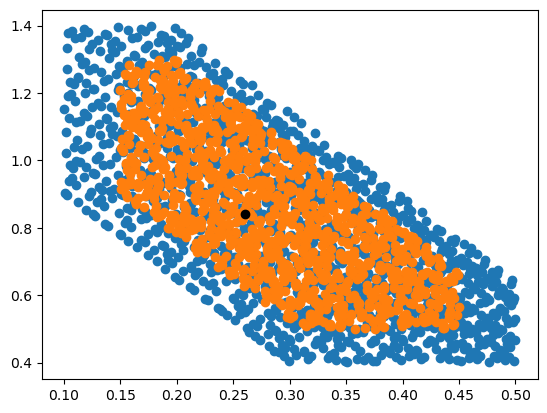

In [6]:
n1 = 28*1300
plt.scatter(theta[:n1:28,0].cpu(), theta[:n1:28,1].cpu())
plt.scatter(theta[n1::28,0].cpu(), theta[n1::28,1].cpu())
plt.scatter(theta_obs[0].cpu(), theta_obs[1].cpu(), c='k')

In [7]:
embed = FCEmbedding(input_dim=304, output_dim=5, num_layers=4, num_hiddens=64)
density_estimator_custom = posterior_nn(model="maf", num_transforms=6, hidden_features=64, num_blocks=3, device=device, embedding_net=embed)
inference = SNPE(density_estimator=density_estimator_custom, device=device, prior=prior_cosmogrid_wide)

density_estimator = inference.append_simulations(theta[:28*1300], x[:28*1300]).train(show_train_summary=True, stop_after_epochs=10, training_batch_size=80, learning_rate=1e-4)
density_estimator = inference.append_simulations(theta[28*1300:], x[28*1300:], proposal=proposal).train(show_train_summary=True, stop_after_epochs=10, training_batch_size=80, learning_rate=5e-5)

 Neural network successfully converged after 89 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 89
        Best validation performance: 1.5781
        -------------------------
        
Using SNPE-C with atomic loss


/home/moon/dgebauer/anaconda3/envs/lfi_gpu/lib/python3.10/site-packages/sbi/inference/snpe/snpe_base.py:602: UserWarning: The proposal you passed is neither the prior nor a `NeuralPosterior` object. If you are an expert user and did so for research purposes, this is fine. If not, you might be doing something wrong: feel free to create an issue on Github.
  warn(


 Neural network successfully converged after 54 epochs.
        -------------------------
        ||||| ROUND 2 STATS |||||:
        -------------------------
        Epochs trained: 54
        Best validation performance: -2.1515
        -------------------------
        


In [1]:
#posterior = inference.build_posterior(density_estimator, sample_with='mcmc')
posterior = inference.build_posterior(density_estimator)
sample = posterior.sample((100000000,), x_obs[0])

_ = make_corner_plot(sample.cpu().numpy(), param_names, theta_obs.cpu().numpy(), smooth=0.5)

NameError: name 'inference' is not defined

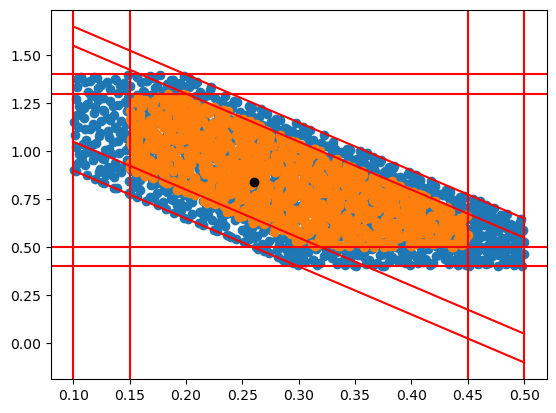

In [ ]:
n1 = 28*1300
plt.scatter(theta[:n1:28,0].cpu(), theta[:n1:28,1].cpu())
plt.scatter(theta[n1::28,0].cpu(), theta[n1::28,1].cpu())
plt.scatter(theta_obs[0].cpu(), theta_obs[1].cpu(), c='k')

xlin = np.linspace(0.1, 0.5,100)

a1=-2.5
b1=1.15
plt.plot(xlin, a1*xlin+b1, c='r')

a2 = -2.5
b2 = 1.9
plt.plot(xlin, a2*xlin+b2, c='r')

a3 = -2.5
b3 = 1.8
plt.plot(xlin, a3*xlin+b3, c='r')

a4 = -2.5
b4 = 1.3
plt.plot(xlin, a4*xlin+b4, c='r')

plt.axvline(0.1, c='r')
plt.axvline(0.5, c='r')
plt.axvline(0.15, c='r')
plt.axvline(0.45, c='r')

plt.axhline(0.4, c='r')
plt.axhline(0.5, c='r')
plt.axhline(1.3, c='r')
plt.axhline(1.4, c='r')

In [ ]:
def check(value):
    if value[1] < -2.5*value[0]+1.15:
        return False
    if value[1] > -2.5*value[0]+1.9:
        return False
    return True

low = np.array([0.1, 0.4]) 
high = np.array([0.5, 1.4])

n=10000000
rand = np.random.rand(n,2)
samples = low + rand * (high - low)

count = 0
for sample in samples:
    if not check(sample):
        count += 1

area = 0.4 * 1 * (1-(count/n))   
print(area)

0.23738772


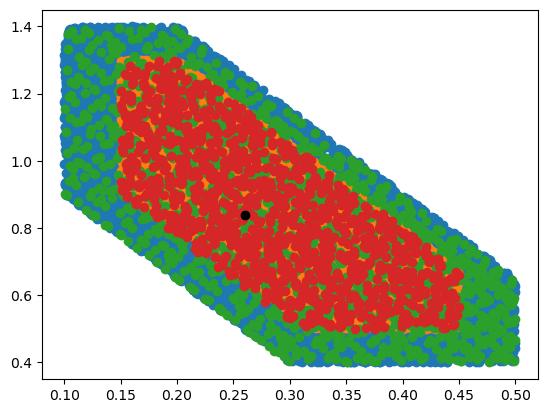

In [ ]:
wid = CosmoGridWide()
nar = CosmoGridNarrow()
wide_sample = wid.rsample((10000,2))
narrow_sample = nar.rsample((10000,2))

plt.scatter(wide_sample[:,0].cpu(), wide_sample[:,1].cpu())
plt.scatter(narrow_sample[:,0].cpu(), narrow_sample[:,1].cpu())
n1 = 28*1300
plt.scatter(theta[:n1:28,0].cpu(), theta[:n1:28,1].cpu())
plt.scatter(theta[n1::28,0].cpu(), theta[n1::28,1].cpu())
plt.scatter(theta_obs[0].cpu(), theta_obs[1].cpu(), c='k')